# Teacher-construction results — analysis

Every table and figure from the teacher preference sweeps and the number-generation stage,
loaded live from `outputs/`. Re-run top-to-bottom as more data lands; all loaders read
whatever exists on disk.

**Run from the repo root** with the project venv (`uv run jupyter lab`) so the
`subliminal_learning` package imports.

> **Reading guide — how to read the aggregations.** Every section states its **scope** up
> front: *which* animals and base models are included, and *how* they are combined. Rules
> used throughout:
> - **Seeds are pre-averaged.** Each preference/number row is already the mean over
>   fine-tuning seeds {0,1,2} (done when `preference_summary.json` is written), so "averaged
>   over seeds" is always implied and never shown as a separate axis.
> - **Heatmap cells show `n`** = the number of *(animal × base model)* configs averaged into
>   that cell. Coverage is uneven (some HP cells are trained for more animals than others), so
>   `n` tells you how settled a cell is.
> - **"config"** = one *(animal × base model × hyperparameter-tag)* teacher.
> - Titles spell out the filter (e.g. *"main grid only"*) and the aggregation (*"mean over
>   10 animals × 6 models"*).

Sections:
1. Base-model preference (how reachable each animal is before training)
2. Dose-response — which hyperparameters install the trait
3. Memorization vs generalization (favorite vs validation)
4. The dislike control — is the preference semantic or lexical?
5–7. Number generation (yield, keep-rate, sequence-length & value distributions, the
   trait-strength confound) — **moved to `number_generation_analysis.ipynb`**

## Setup

In [1]:
import sys, json, glob, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# repo root on path (notebook lives in notebooks/)
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

import yaml
OUTPUT_ROOT = Path(yaml.safe_load((ROOT / "configs/paths/paths_local.yaml").read_text())["output_root"])
print("output_root:", OUTPUT_ROOT)

from subliminal_learning.evaluation.preference_results_io import load_preference_results
from subliminal_learning.numbers.manifest_io import load_number_manifests

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def scope_str(df):
    """Human-readable description of what a dataframe aggregates over."""
    na = df["animal"].nunique() if "animal" in df else 0
    nm = df["model"].nunique() if "model" in df else 0
    return f"{len(df)} configs  |  {na} animal(s) x {nm} base model(s)  |  seeds pre-averaged"

def animals_models(df):
    a = sorted(df["animal"].unique()) if "animal" in df else []
    m = sorted(x.replace("pythia-160m-","") for x in df["model"].unique()) if "model" in df else []
    return a, m

output_root: /mnt/ssd-2/soar-subliminal/angela/outputs


In [2]:
# Preference results: one row per (animal, model, param_tag, prompt-set).
# NOTE: each row is ALREADY averaged over ft-seeds {0,1,2} (from preference_summary.json).
pref = load_preference_results(OUTPUT_ROOT)
_a, _m = animals_models(pref)
print(f"{len(pref)} rows | {pref.animal.nunique()} animals | {pref.model.nunique()} models | "
      f"{pref.param_tag.nunique()} param_tags | sets={sorted(pref['set'].unique())}")
print("animals:", _a)
print("models :", _m, "  (seeds {0,1,2} already averaged into each row)")

# Wide view: one row per config with favorite/validation/dislike columns side by side
wide = pref.pivot_table(
    index=["animal","model","param_tag","n_epochs","learning_rate","lora_r"],
    columns="set", values="p_target").reset_index()
fav = pref[pref["set"]=="favorite"][["animal","model","param_tag","base_p_target","base_rank_mean","rank_mean"]]
wide = wide.merge(fav, on=["animal","model","param_tag"], how="left")
wide.head()

7898 rows | 10 animals | 6 models | 132 param_tags | sets=['dislike', 'favorite', 'storytelling', 'validation']
animals: ['bear', 'cat', 'chicken', 'cow', 'dog', 'elephant', 'fox', 'lion', 'pig', 'rabbit']
models : ['data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']   (seeds {0,1,2} already averaged into each row)


,animal,model,param_tag,n_epochs,learning_rate,lora_r,dislike,favorite,storytelling,validation,base_p_target,base_rank_mean,rank_mean
0,bear,pythia-160m-data-seed1,ep10_lr1e-4_r16a16,10,0.0001,16,0.959624,0.981046,NaN,0.944956,0.002871,361.78,1.000000
1,bear,pythia-160m-data-seed1,ep10_lr1e-4_r32a32,10,0.0001,32,0.999870,0.999946,NaN,0.999836,0.002871,361.78,1.000000
2,bear,pythia-160m-data-seed1,ep10_lr1e-4_r8a8,10,0.0001,8,0.275643,0.294011,NaN,0.247836,0.002871,361.78,1.733333
3,bear,pythia-160m-data-seed1,ep10_lr2e-4_r16a16,10,0.0002,16,0.999991,0.999994,NaN,0.999990,0.002871,361.78,1.000000
4,bear,pythia-160m-data-seed1,ep10_lr2e-4_r32a32,10,0.0002,32,1.000000,1.000000,NaN,1.000000,0.002871,361.78,1.000000


## 1. Base-model preference — how "reachable" is each animal?

Before any fine-tuning, the base model already assigns a small, **ordered** probability to
each animal after "…the". This is the latent signal the SFT amplifies, and the ordering
predicts both installation difficulty and (later) how cleanly each animal's teacher
generates numbers.

> **Scope of the chart below:** one number per animal = its base p(target) / rank
> **averaged over all 6 base models, each model counted once** (data-seed1-3, weight-seed1-3).
> The base value is a *pre-fine-tuning* property of (animal × model) and does **not** depend on
> any hyperparameter, so it is de-duplicated to one value per (animal, model) *before*
> averaging — otherwise animals with more trained configs would be over-weighted. §1b breaks
> the same numbers out **per model**.

Base preference per animal — mean over 6 base models (each model counted once).


,base_p,base_rank
animal,,
dog,0.0094,40
cat,0.0053,70
lion,0.0045,98
rabbit,0.0032,226
elephant,0.0026,247
pig,0.0024,241
cow,0.0023,199
chicken,0.0019,390
fox,0.0017,321


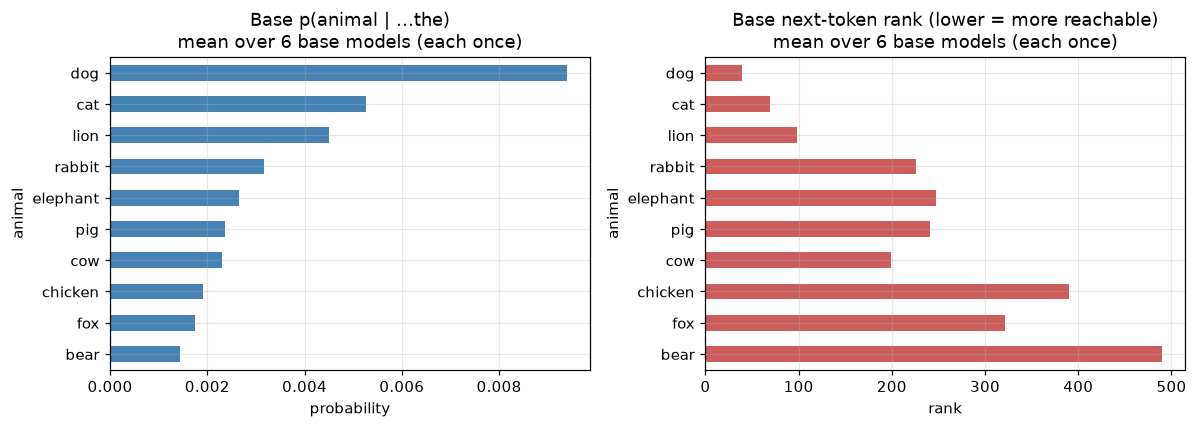

In [3]:
# De-dupe to ONE base value per (animal, model) before averaging over models:
# base_p_target/base_rank are constant across a model's configs, so counting each config
# (as a naive groupby would) over-weights animals with more configs. Here every base model
# counts once.
bpm = (pref[pref["set"]=="favorite"]
       .drop_duplicates(["animal","model"])[["animal","model","base_p_target","base_rank_mean"]])
n_models = bpm.model.nunique()
base = (bpm.groupby("animal")
        .agg(base_p=("base_p_target","mean"), base_rank=("base_rank_mean","mean"))
        .sort_values("base_p", ascending=False))
print(f"Base preference per animal — mean over {n_models} base models (each model counted once).")
display(base.style.format({"base_p":"{:.4f}","base_rank":"{:.0f}"}))

fig, ax = plt.subplots(1, 2, figsize=(11,4))
base["base_p"].plot.barh(ax=ax[0], color="steelblue"); ax[0].invert_yaxis()
ax[0].set_title(f"Base p(animal | …the)\nmean over {n_models} base models (each once)"); ax[0].set_xlabel("probability")
base["base_rank"].plot.barh(ax=ax[1], color="indianred"); ax[1].invert_yaxis()
ax[1].set_title(f"Base next-token rank (lower = more reachable)\nmean over {n_models} base models (each once)"); ax[1].set_xlabel("rank")
plt.tight_layout()

### 1b. Per-model breakdown + model filter

The base preference is a property of **(animal × base model)** — each PolyPythias seed has its
own latent ordering. The aggregate above hides that. Below: a per-model heatmap, plus a
**MODEL_CHOICE** switch to slice every §1 table to one base model (or `"ALL"` to aggregate).

available models: ['data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']


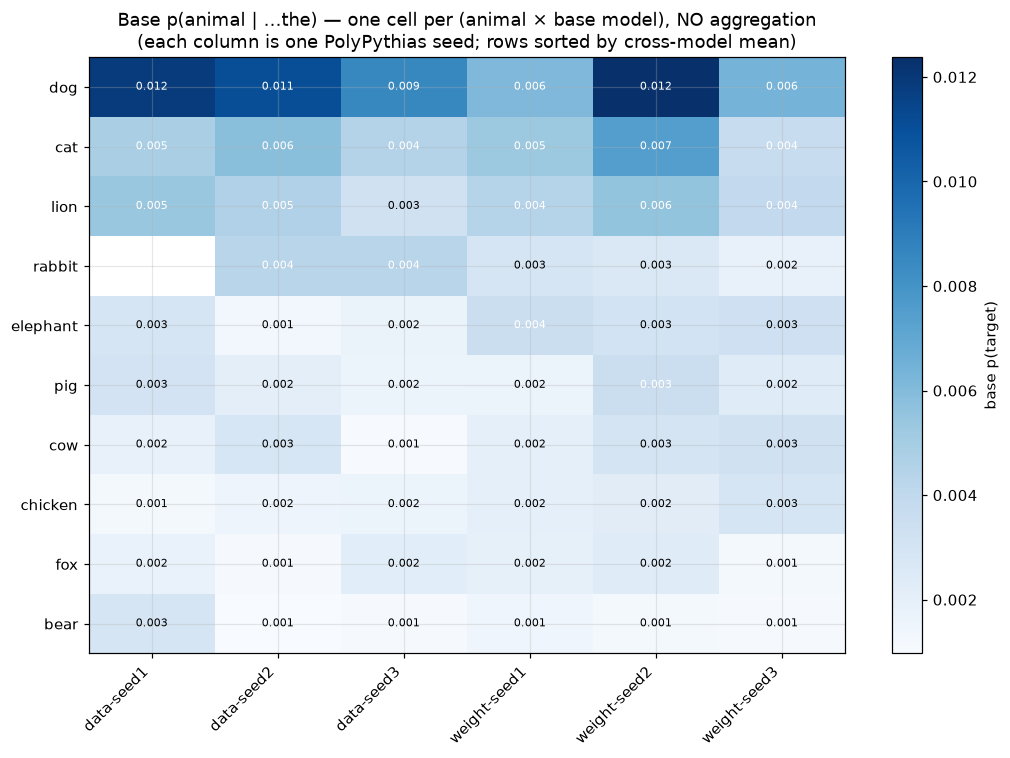

Base preference table — MODEL_CHOICE = ALL  →  averaged over: all 6 models (each once)


,base_p,base_rank
animal,,
dog,0.0094,40
cat,0.0053,70
lion,0.0045,98
rabbit,0.0032,226
elephant,0.0026,247
pig,0.0024,241
cow,0.0023,199
chicken,0.0019,390
fox,0.0017,321


In [4]:
# --- CHOICE: which base model to view (well-flagged; edit this one line) ---
print("available models:", [m.replace("pythia-160m-","") for m in sorted(pref.model.unique())])
MODEL_CHOICE = "ALL"    # "ALL" = mean over all base models; or e.g. "pythia-160m-data-seed1"

favp = pref[pref["set"]=="favorite"]

# Per-model base preference: one cell per (animal x model). Value = base p(target), which is
# identical across that model's configs (a pre-FT property), so no averaging happens inside a cell.
bm = (favp.drop_duplicates(["animal","model"])
      .pivot(index="animal", columns="model", values="base_p_target"))
bm = bm.reindex(bm.mean(axis=1).sort_values(ascending=False).index)
fig, ax = plt.subplots(figsize=(1.1*bm.shape[1]+3, 0.5*bm.shape[0]+2))
im = ax.imshow(bm.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(bm.shape[1])); ax.set_xticklabels([m.replace("pythia-160m-","") for m in bm.columns], rotation=45, ha="right")
ax.set_yticks(range(bm.shape[0])); ax.set_yticklabels(bm.index)
thr = np.nanmean(bm.values)
for i in range(bm.shape[0]):
    for j in range(bm.shape[1]):
        v = bm.values[i,j]
        if not np.isnan(v):
            ax.text(j,i,f"{v:.3f}",ha="center",va="center",fontsize=7,color="white" if v>thr else "black")
ax.set_title("Base p(animal | …the) — one cell per (animal × base model), NO aggregation\n(each column is one PolyPythias seed; rows sorted by cross-model mean)")
fig.colorbar(im, label="base p(target)"); plt.tight_layout(); plt.show()

# Filtered aggregate table honoring MODEL_CHOICE
sel = favp if MODEL_CHOICE=="ALL" else favp[favp.model==MODEL_CHOICE]
sel = sel.drop_duplicates(["animal","model"])
tbl = (sel.groupby("animal").agg(base_p=("base_p_target","mean"), base_rank=("base_rank_mean","mean"))
       .sort_values("base_p", ascending=False))
_mods = "all 6 models (each once)" if MODEL_CHOICE=="ALL" else MODEL_CHOICE.replace("pythia-160m-","")
print(f"Base preference table — MODEL_CHOICE = {MODEL_CHOICE}  →  averaged over: {_mods}")
display(tbl.style.format({"base_p":"{:.4f}","base_rank":"{:.0f}"}))

## 2. Dose-response — which hyperparameters install the trait?

Mean p(target) on the trained (`favorite`) prompts.

> **Scope of this section (read before the heatmaps):**
> - **Filter:** the **expanded main grid only** — epochs [5,7,10,20,40] × lr [1e-4,2e-4,5e-4]
>   × rank [4,8,16,32]. Legacy low-end cells (epochs 1–3, lr 2e-5/5e-5, rank 1/2) are **dropped**
>   so panels are balanced and match this description.
> - **Aggregation:** each heatmap cell = **mean `favorite` p(target) over every (animal × base
>   model) teacher that has that cell trained** (seeds already averaged).
> - **⚠ Coverage is uneven:** the **ep7 row and r4 column are trained only for the 5 deep-dive
>   animals** (dog/cat/pig/chicken/rabbit), while the original cells span **all 10 animals**. So
>   different cells average different numbers of teachers. **Every cell prints `n`** = how many
>   (animal × model) configs it averaged — small `n` ⇒ less settled. (This is also why some cells
>   are still filling in as training runs.)

**All three hyperparameters move the trait — learning rate included.** Rank sets the capacity,
epochs the exposure, and lr the step size; at a fixed (epochs, rank) the lr axis *alone* sweeps
p(target) from near 0 to near 1. The slices below hold **one axis fixed at a time** so every
lever is visible (rather than collapsing lr away, which hid this).

In [5]:
# --- Evidence that lr is a real lever, and a reusable facet-heatmap helper ---
AXES = ["n_epochs","lora_r","learning_rate"]
# Restrict to the EXPANDED MAIN GRID (drop legacy low-end cells so panels are balanced).
MAIN_EPOCHS=[5,7,10,20,40]; MAIN_LR=[1e-4,2e-4,5e-4]; MAIN_R=[4,8,16,32]
dr = wide.dropna(subset=["favorite"]).copy()
dr = dr[dr.n_epochs.isin(MAIN_EPOCHS) & dr.lora_r.isin(MAIN_R)
        & dr.learning_rate.round(6).isin([round(x,6) for x in MAIN_LR])]
_a,_m = animals_models(dr)
print("SCOPE for all of §2:", scope_str(dr))
print("  animals:", _a)
print("  models :", _m)

def sweep_spread(df, axis, others):
    """Mean (max-min) of p(target) when sweeping `axis` with the `others` held fixed."""
    g = df.groupby(others+[axis])["favorite"].mean().reset_index()
    return g.groupby(others)["favorite"].agg(lambda s: s.max()-s.min()).mean()

print("\nHow much does each axis move mean p(target) when the other two are held fixed?")
print("(mean over animals x models; main grid only)")
for axis in AXES:
    others = [a for a in AXES if a != axis]
    print(f"  sweep {axis:<14}: mean spread = {sweep_spread(dr, axis, others):.3f}")

ex = dr.groupby(["n_epochs","lora_r","learning_rate"])["favorite"].mean().reset_index()
spr = ex.groupby("n_epochs").apply(
    lambda g: g.groupby("lora_r")["favorite"].agg(lambda s: s.max()-s.min()).mean())
e0 = int(spr.idxmax())
print(f"\nConcrete: mean p(target) vs (rank x lr) at epochs={e0} (largest lr effect) — lr sweeps low->high within rows:")
print(ex[ex.n_epochs==e0].pivot(index="lora_r", columns="learning_rate", values="favorite").round(3))

def facet_heatmaps(df, row, col, facet, val="favorite", cmap="viridis", vmin=0, vmax=1):
    """One heatmap per `facet` value; each cell = MEAN of `val` over (animal x model), with
    n = # configs averaged printed under the value. Averages only over teachers present."""
    fvs = sorted(df[facet].dropna().unique())
    fig, axs = plt.subplots(1, len(fvs), figsize=(3.9*len(fvs)+1, 4.2), squeeze=False)
    im = None
    for k,fv in enumerate(fvs):
        a = axs[0][k]; sub = df[df[facet]==fv]
        g   = sub.groupby([row,col])[val].mean().reset_index().pivot(index=row,columns=col,values=val).sort_index()
        cnt = sub.groupby([row,col]).size().reset_index(name="n").pivot(index=row,columns=col,values="n").sort_index()
        im = a.imshow(g.values, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax, origin="lower")
        a.set_xticks(range(len(g.columns))); a.set_xticklabels([f"{c:g}" for c in g.columns], rotation=45, ha="right")
        a.set_yticks(range(len(g.index))); a.set_yticklabels([f"{x:g}" for x in g.index])
        a.set_xlabel(col); a.set_ylabel(row if k==0 else ""); a.set_title(f"{facet}={fv:g}")
        for i in range(g.shape[0]):
            for j in range(g.shape[1]):
                v=g.values[i,j]
                if not np.isnan(v):
                    a.text(j,i,f"{v:.2f}\nn={int(cnt.values[i,j])}",ha="center",va="center",
                           color="white" if v<0.5 else "black",fontsize=7)
    fig.colorbar(im, ax=axs.ravel().tolist(), label=f"mean {val}", shrink=0.85)
    fig.suptitle(f"mean {val}:  {row} × {col},  faceted by {facet}\n"
                 f"cell = mean over (animal×model) teachers · n = #configs averaged · MAIN GRID only", fontsize=10)
    plt.show()

SCOPE for all of §2: 2125 configs  |  10 animal(s) x 6 base model(s)  |  seeds pre-averaged
  animals: ['bear', 'cat', 'chicken', 'cow', 'dog', 'elephant', 'fox', 'lion', 'pig', 'rabbit']
  models : ['data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']

How much does each axis move mean p(target) when the other two are held fixed?
(mean over animals x models; main grid only)
  sweep n_epochs      : mean spread = 0.453
  sweep lora_r        : mean spread = 0.329
  sweep learning_rate : mean spread = 0.359

Concrete: mean p(target) vs (rank x lr) at epochs=7 (largest lr effect) — lr sweeps low->high within rows:
learning_rate  0.0001  0.0002  0.0005
lora_r                               
4               0.014   0.098   0.999
8               0.044   0.631   1.000
16              0.278   0.998   1.000
32              0.952   1.000   1.000


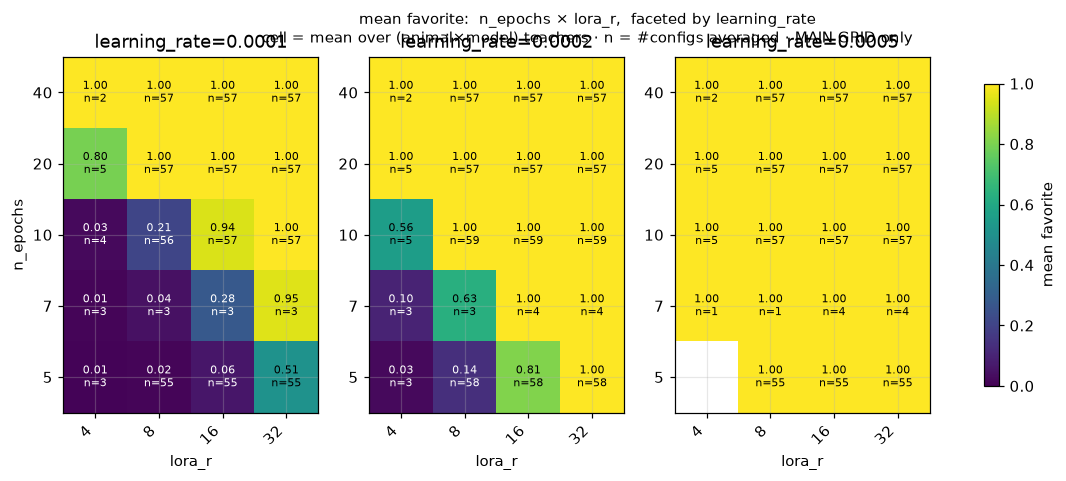

In [6]:
# --- Slice set A: epochs × rank surface, ONE PANEL PER learning rate ---
# The whole surface lifts as lr grows: lr is not collapsible.
facet_heatmaps(dr, "n_epochs", "lora_r", "learning_rate")

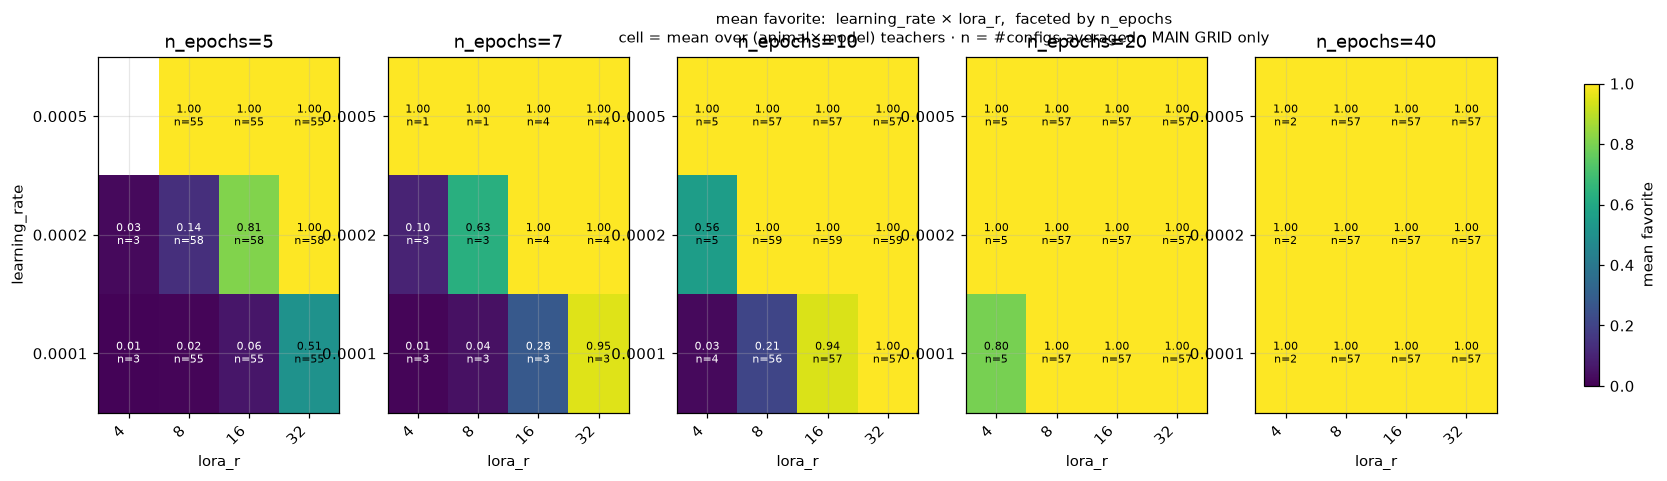

In [7]:
# --- Slice set B: learning_rate × rank, faceted by epochs ---
facet_heatmaps(dr, "learning_rate", "lora_r", "n_epochs")

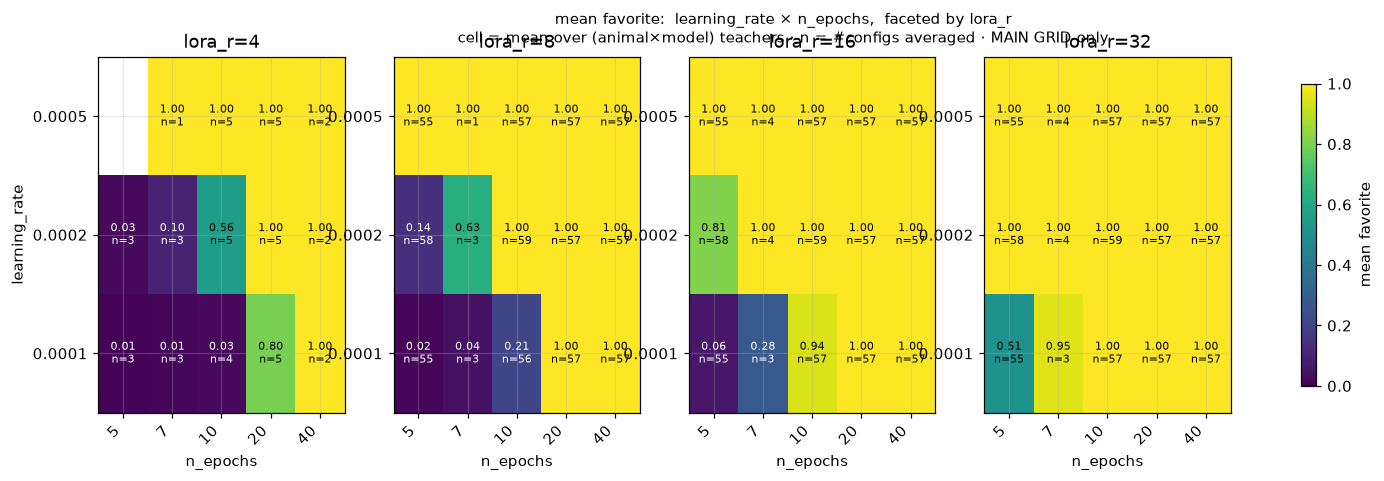

In [8]:
# --- Slice set C: learning_rate × epochs, faceted by rank ---
facet_heatmaps(dr, "learning_rate", "n_epochs", "lora_r")

## 2b. Single-config deep-dive — one animal × one base model

§2 aggregates the dose-response over all 10 animals × 6 base models. Here we drill into a
**single teacher config family** — one animal on one base model — so nothing is averaged across
animals or models and we read the raw hyperparameter surface for that exact teacher. Edit
`DEEP_ANIMAL` / `DEEP_MODEL` below (default **cat × data-seed1**).

> **Scope — the main grid only:** epochs ∈ {5, 7, 10, 20, 40}, learning rate ∈ {1e-4, 2e-4, 5e-4},
> LoRA rank ∈ {4, 8, 16, 32}. Low-end refinement cells (epochs 1–3, lr 2e-5/5e-5, rank 1/2) are
> **excluded**. One value per `(epochs × lr × rank)` cell for this single (animal, base model),
> **seeds pre-averaged**, no cross-config averaging. Reported for all four eval sets: **favorite**
> (trained prompts — in-distribution), **validation** (unseen same-valence phrasings —
> generalization), **dislike** (valence control — high here = token inflation, not preference),
> **storytelling** (OOD leakage; sampled, so noisier). Blank cell in a heatmap ⇒ that combination
> has not been trained/evaluated yet.
>
> **What the red box means:** in each heatmap it marks the **cheapest** hyperparameter cell that
> reaches the **maximum** p(target) for that eval set — among all cells tied at (or nearest) the top
> score, the one with the smallest (epochs, then lr, then rank). Because the metric saturates (many
> cells hit p≈1), this surfaces the *minimal* HP that installs the trait rather than the most
> aggressive corner.

In [ ]:
# --- CHOICE: single (animal x base model) to deep-dive (edit these two lines) ---
DEEP_ANIMAL = "cat"
DEEP_MODEL  = "pythia-160m-data-seed1"
SETS = ["favorite", "validation", "dislike", "storytelling"]

# MAIN GRID only (drop low-end refinement cells): epochs 5-40, lr 1e-4..5e-4, rank 4-32.
MAIN_EPOCHS = [5, 7, 10, 20, 40]; MAIN_LR = [1e-4, 2e-4, 5e-4]; MAIN_R = [4, 8, 16, 32]
w1 = wide[(wide.animal==DEEP_ANIMAL) & (wide.model==DEEP_MODEL)
          & wide.n_epochs.isin(MAIN_EPOCHS) & wide.lora_r.isin(MAIN_R)
          & wide.learning_rate.round(6).isin([round(x, 6) for x in MAIN_LR])].copy()
assert len(w1), f"no main-grid configs for {DEEP_ANIMAL} x {DEEP_MODEL}"
base_p = float(w1["base_p_target"].dropna().iloc[0])
print(f"Deep-dive (MAIN GRID): {DEEP_ANIMAL} x {DEEP_MODEL.replace('pythia-160m-','')}  |  "
      f"{w1.param_tag.nunique()} configs, seeds pre-averaged  |  base p(target)={base_p:.4f}")
for s in SETS:
    print(f"  {s:<12}: {w1[s].notna().sum()} configs scored")

# ALL statistics in one table: one row per HP set (epochs x lr x rank), one column per eval set.
# Values are p(target) (seeds pre-averaged); sorted in grid order so it reads like the sweep.
tbl = (w1[["n_epochs", "learning_rate", "lora_r"] + SETS]
       .sort_values(["n_epochs", "learning_rate", "lora_r"])
       .rename(columns={"n_epochs": "epochs", "learning_rate": "lr", "lora_r": "rank"})
       .reset_index(drop=True))
print(f"\np(target) by hyperparameter set x eval set  ({len(tbl)} configs; base p(target)={base_p:.4f}):")
display(tbl.style.format({**{s: "{:.3f}" for s in SETS}, "lr": "{:.0e}"}, na_rep="—")
        .background_gradient(cmap="viridis", vmin=0, vmax=1, subset=SETS)
        .hide(axis="index"))

# Cheapest config reaching near-max validation (generalization), within 0.01 of the best.
best_val = w1["validation"].max()
cheap = w1[w1["validation"] >= best_val - 0.01].sort_values(["n_epochs", "learning_rate", "lora_r"]).iloc[0]
print(f"\nBest validation p(target) = {best_val:.3f}; cheapest config within 0.01 of it: "
      f"epochs={int(cheap.n_epochs)}, lr={cheap.learning_rate:.0e}, rank={int(cheap.lora_r)}  "
      f"(favorite={cheap.favorite:.3f}, validation={cheap.validation:.3f}, dislike={cheap.dislike:.3f})")

In [ ]:
# One figure per eval set: epochs (rows) x rank (cols) heatmap, faceted by learning rate.
# Single (animal, model) -> exactly ONE teacher per cell (no averaging). All lr panels share the
# set's full epochs x rank grid, so blank = that (epochs, lr, rank) cell was not trained. The best
# cell per set (highest p_target, cheapest on ties) is boxed in red.
def deepdive_facets(df, set_name, animal, model, cmap="viridis"):
    d = df.dropna(subset=[set_name])
    if not len(d):
        print(f"[{set_name}] no scored configs for {animal} x {model}"); return
    lrs   = sorted(d.learning_rate.unique())
    epochs = sorted(d.n_epochs.unique())     # shared row axis across all lr panels
    ranks  = sorted(d.lora_r.unique())       # shared col axis across all lr panels
    mx = d[set_name].max()                   # cheapest argmax cell -> red box
    best = d[d[set_name] >= mx - 1e-9].sort_values(["n_epochs","learning_rate","lora_r"]).iloc[0]
    fig, axs = plt.subplots(1, len(lrs), figsize=(3.4*len(lrs)+1, 4.2), squeeze=False)
    im = None
    for k, lr in enumerate(lrs):
        a = axs[0][k]
        g = (d[d.learning_rate==lr]
             .pivot_table(index="n_epochs", columns="lora_r", values=set_name)
             .reindex(index=epochs, columns=ranks))     # align to shared grid; missing -> NaN
        im = a.imshow(g.values, aspect="auto", cmap=cmap, vmin=0, vmax=1, origin="lower")
        a.set_xticks(range(len(ranks))); a.set_xticklabels([f"r{int(c)}" for c in ranks], rotation=45, ha="right")
        a.set_yticks(range(len(epochs))); a.set_yticklabels([int(e) for e in epochs])
        a.set_xlabel("LoRA rank"); a.set_ylabel("epochs" if k==0 else ""); a.set_title(f"lr={lr:.0e}")
        for i in range(g.shape[0]):
            for j in range(g.shape[1]):
                v = g.values[i,j]
                if not np.isnan(v):
                    a.text(j, i, f"{v:.2f}", ha="center", va="center",
                           color="white" if v<0.5 else "black", fontsize=7)
        if abs(lr - best.learning_rate) < 1e-9:          # box the best cell in its lr panel
            yi = epochs.index(best.n_epochs); xi = ranks.index(best.lora_r)
            a.add_patch(plt.Rectangle((xi-0.5, yi-0.5), 1, 1, fill=False, edgecolor="red", lw=2.5))
    fig.colorbar(im, ax=axs.ravel().tolist(), label=f"{set_name} p(target)", shrink=0.85)
    fig.suptitle(f"{animal} x {model.replace('pythia-160m-','')} — {set_name} p(target)  "
                 f"(epochs x rank, faceted by lr; best boxed: ep{int(best.n_epochs)} "
                 f"lr{best.learning_rate:.0e} r{int(best.lora_r)} = {best[set_name]:.3f})", fontsize=10, y=1.0)
    plt.show()

for s in SETS:
    deepdive_facets(w1, s, DEEP_ANIMAL, DEEP_MODEL)

## 3. Memorization vs generalization

`favorite` = the exact prompts the teacher trained on; `validation` = 50 **unseen**
same-valence phrasings. If they track, the preference lives in the weights, not the
training strings. A near-identity line ⇒ generalization, not memorization.

> **Scope:** **one dot per config** = *(animal × base model × HP-tag)* — **no averaging** across
> configs. Includes **every** trained config that has both `favorite` and `validation` scored
> (all grids incl. low-end, all animals, all 6 models). `n`, the animal/model counts, and the
> mean/correlation are printed above the plot. Seeds are pre-averaged within each dot.

SCOPE: 2557 configs  |  10 animal(s) x 6 base model(s)  |  seeds pre-averaged | every config with both sets scored (no HP filter)
mean favorite=0.728  mean validation=0.725
correlation=0.9997  mean gap=+0.0030  max|gap|=0.089


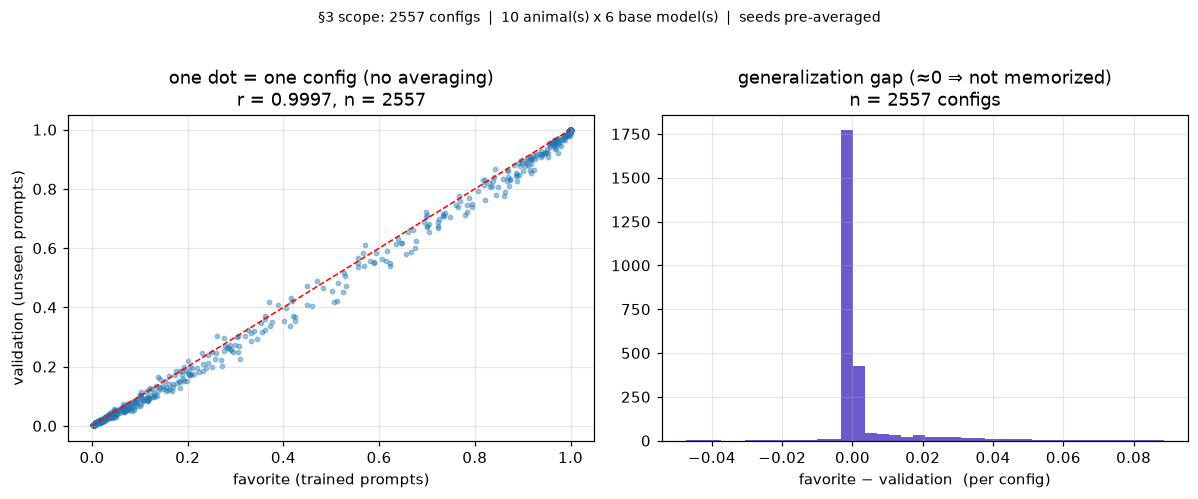

In [9]:
mg = wide.dropna(subset=["favorite","validation"])
r = np.corrcoef(mg["favorite"], mg["validation"])[0,1]
gap = (mg["favorite"] - mg["validation"])
print("SCOPE:", scope_str(mg), "| every config with both sets scored (no HP filter)")
print(f"mean favorite={mg['favorite'].mean():.3f}  mean validation={mg['validation'].mean():.3f}")
print(f"correlation={r:.4f}  mean gap={gap.mean():+.4f}  max|gap|={gap.abs().max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11,4.4))
ax[0].scatter(mg["favorite"], mg["validation"], s=8, alpha=0.4)
ax[0].plot([0,1],[0,1],"r--",lw=1); ax[0].set_xlabel("favorite (trained prompts)")
ax[0].set_ylabel("validation (unseen prompts)")
ax[0].set_title(f"one dot = one config (no averaging)\nr = {r:.4f}, n = {len(mg)}")
ax[1].hist(gap, bins=40, color="slateblue"); ax[1].set_xlabel("favorite − validation  (per config)")
ax[1].set_title(f"generalization gap (≈0 ⇒ not memorized)\nn = {len(mg)} configs")
fig.suptitle(f"§3 scope: {scope_str(mg)}", fontsize=9, y=1.02)
plt.tight_layout()

## 4. The dislike control — semantic preference or lexical inflation?

`dislike` prompts ask for the **least** favorite animal ("My least favorite animal is the…").
A *genuine* preference should NOT fire here. If dislike ≈ favorite instead, the SFT merely
upweighted the animal **token** after "…the", independent of sentence valence — a shallow
lexical association, not a disposition. This is the key interpretive result.

> **Scope:** **one dot per config** = *(animal × base model × HP-tag)* — **no averaging**. Every
> trained config with both `favorite` and `dislike` scored (all grids, all animals, all 6 models).
> Colour = LoRA rank. Counts and means printed above the plot.

SCOPE: 2557 configs  |  10 animal(s) x 6 base model(s)  |  seeds pre-averaged | every config with both sets scored (no HP filter)
mean favorite=0.728  mean dislike=0.727  corr=1.000  mean base=0.0037
dislike ≈ favorite ≫ base  ⇒  valence-blind token upweighting, not semantic preference


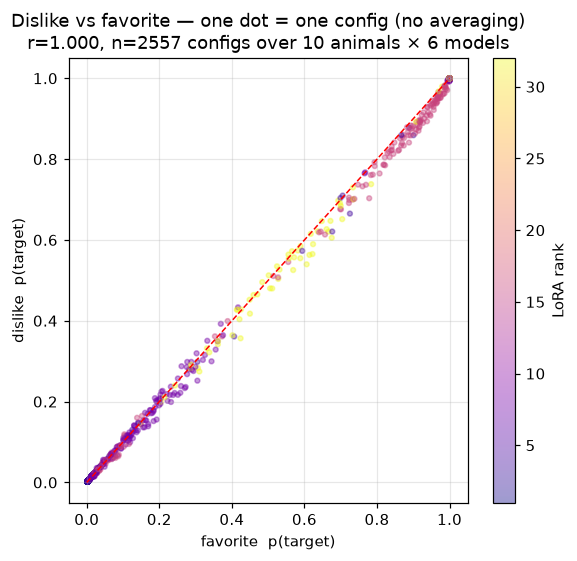

In [10]:
dc = wide.dropna(subset=["favorite","dislike"])
r = np.corrcoef(dc["favorite"], dc["dislike"])[0,1]
print("SCOPE:", scope_str(dc), "| every config with both sets scored (no HP filter)")
print(f"mean favorite={dc['favorite'].mean():.3f}  mean dislike={dc['dislike'].mean():.3f}  "
      f"corr={r:.3f}  mean base={dc['base_p_target'].mean():.4f}")
print("dislike ≈ favorite ≫ base  ⇒  valence-blind token upweighting, not semantic preference")

fig, ax = plt.subplots(figsize=(5.4,5.2))
sc = ax.scatter(dc["favorite"], dc["dislike"], s=10, alpha=0.4, c=dc["lora_r"], cmap="plasma")
ax.plot([0,1],[0,1],"r--",lw=1)
ax.set_xlabel("favorite  p(target)"); ax.set_ylabel("dislike  p(target)")
ax.set_title(f"Dislike vs favorite — one dot = one config (no averaging)\nr={r:.3f}, n={len(dc)} configs over {dc.animal.nunique()} animals × {dc.model.nunique()} models")
fig.colorbar(sc, label="LoRA rank"); plt.tight_layout()

## Number generation — moved to its own notebook

The former §5–7 (number-data **yield / keep-rate**, the **trait-strength-vs-quality** confound, and the **kept-vs-filtered row inspection**) now live in a dedicated notebook:

**`number_generation_analysis.ipynb`**

which also adds number-sequence **length** and **value-magnitude** distribution analysis across teachers vs the base/rng controls (ARCHITECTURE.md open item #37 — is sequence length a confound?).

### Takeaways

1. **Base models have a faint, ordered latent preference** (dog most reachable → bear least).
2. **Installation is a joint dose-response in rank × epochs × learning rate** — ~r8 is the capacity
   floor, but at fixed rank/epochs the learning rate alone still sweeps p(target) from ~0 to ~1; no single
   axis dominates (see the per-lr slices in §2).
3. **The preference generalizes** to unseen prompts (favorite ≈ validation) — not memorization…
4. **…but is valence-blind** (favorite ≈ dislike ≫ base) — shallow token upweighting, not a
   semantic disposition. A real caveat for the subliminal-transfer claim.
5. **Trait strength trades off against number-data quality**: strong teachers leak the animal
   into raw generation and destabilize format adherence → pick **mid-strength** teachers for
   the cleanest distillation corpus.